# Axis 5 — Training and support

**Owner: Member 5 · Branch: `axis-5` · Status: starting notebook, not a completed investigation.**

**Question:** How do respondents learn AI skills and what matters for adoption?

**Use for the sponsor:** Suggest one support activity and a way of evaluating it in a pilot.

The proposed sponsor is a DINUM team planning an AI coding-assistant pilot. These French survey respondents are not a sample of DINUM staff. Use the shared population and denominator rules before changing them.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open this notebook from the project root or its notebooks folder.")
sys.path.insert(0, str(ROOT))
from src.data import ensure_data, load_responses, load_schema
from src.population import prepare_population

ensure_data()
population = prepare_population(load_responses())
schema = load_schema()
print("2026 · France · coding as primary job · eligible respondents:", len(population))

2026 · France · coding as primary job · eligible respondents: 628


## 1. Check the fields and the answering population

In [2]:
fields = ['LearnAI', 'LearnAIHow', 'AIAdopt']
display(schema.loc[schema["column"].isin(fields), ["column", "question", "sub", "transformation"]])
display(pd.DataFrame({"answered": population[fields].notna().sum(),
                      "unanswered": population[fields].isna().sum()}))

,column,question,sub,transformation
10,LearnAI,"In the last year, did you spend time learning ...",NaN,Original answer
11,LearnAIHow,How did you learn to code for AI in the past y...,NaN,"Distinct selections, semicolon-separated"
152,AIAdopt,When you or your organization decides whether ...,NaN,"Distinct selections, semicolon-separated"


,answered,unanswered
LearnAI,628,0
LearnAIHow,434,194
AIAdopt,337,291


## 2. A first descriptive view
This is a starting calculation. Record a factual observation and a separate question after inspecting it.

,answer,respondents,share_pct
0,"Yes, both on my own and at work",216,34.394904
1,No,182,28.980892
2,"Yes, at work",131,20.859873
3,"Yes, on my own",99,15.764331


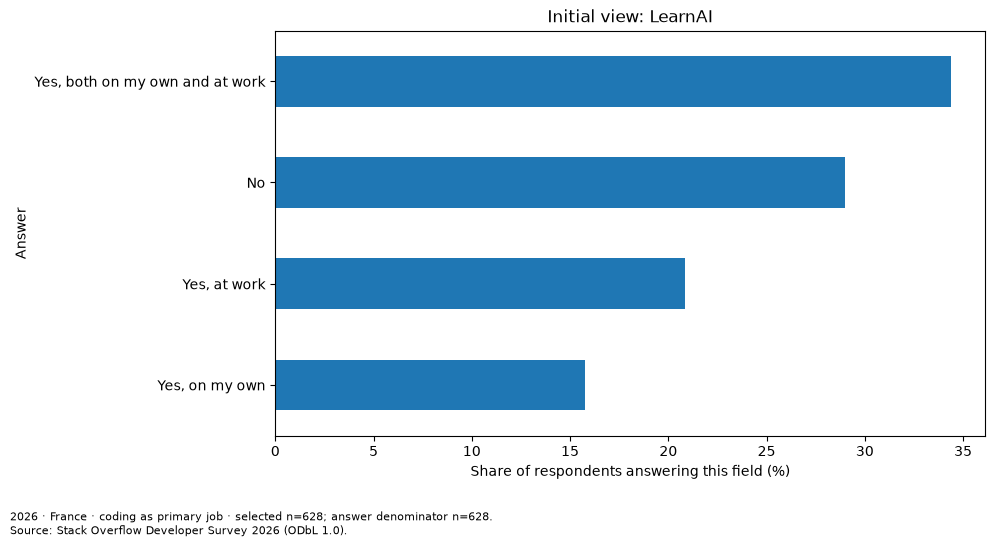

In [3]:
from src.analysis.axis_5 import summarise

column = 'LearnAI'
table, answered_n = summarise(population, column)
display(table.head(10))
ax = table.head(10).iloc[::-1].plot.barh(x="answer", y="share_pct", legend=False, figsize=(10, 5))
ax.set(title="Initial view: " + column, xlabel="Share of respondents answering this field (%)", ylabel="Answer")
plt.figtext(.01, -.08, f"2026 · France · coding as primary job · selected n={len(population)}; answer denominator n={answered_n}.\nSource: Stack Overflow Developer Survey 2026 (ODbL 1.0).", fontsize=8)
plt.tight_layout()
plt.show()

## 3. Work still to do — Member 5

1. Explore several useful views and write separate **I notice** / **I wonder** entries.
2. Formulate a testable hypothesis arising from those observations.
3. Compare a learning or adoption subgroup. Check question routing and missing answers, consider an alternative explanation and distinguish training participation from demonstrated learning benefit.
4. Explain what the evidence supports, what remains uncertain and what cannot be concluded.
5. Add one useful interaction and one clear view to `views/axis_5.py`, with calculations in `src/analysis/axis_5.py`.
6. Check the shared app and explain the code. Ask the assigned reviewer to read the PR.

Write your own analysis below this plan. The starter calculation is not a finished individual submission.